# Skala ratingowa i backtest klas, próg decyzyjny z funkcji zysku, porównanie decyzji i analiza kontrfaktyczna

----
## 0. Importy

In [1]:
import sys, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from lime.lime_tabular import LimeTabularExplainer
from src import config as cfg
from src.data import load_data, load_splits
from src.features import build_base_frame, CAT_COLS
from src.calibration import apply_cal, shift
from src.explain import shap_lgbm, shap_logit, LimeAdapter, lime_weights
from src.rating import (RATING_LABELS, P_STAR, MARGIN, LGD, rating, scale_table, backtest, economics, Counterfactual)
warnings.filterwarnings('ignore')
plt.style.use('default')

----
## 1. Skala ratingowa

In [2]:
df = load_data(); splits = load_splits(); y = df[cfg.TARGET]
va, te = splits['valid'], splits['test']
cal = pd.read_csv(cfg.ROOT / 'outputs/predictions/pd_skalibrowane.csv')
PD = {m: {s: g.set_index('id').loc[ids, 'pd_4proc'].to_numpy() for s, ids in [('valid', va), ('test', te)]
          for _ in [0] for g in [cal[(cal.model == m) & (cal.zbior == s)]]} for m in ['logit', 'black-box']}

Y = {'valid': y.loc[va].to_numpy(), 'test': y.loc[te].to_numpy()}
print(f'p* = MARGIN / (MARGIN + LGD) = {MARGIN} / ({MARGIN} + {LGD}) = {P_STAR:.4f}')
scale_table()

p* = MARGIN / (MARGIN + LGD) = 0.1 / (0.1 + 0.45) = 0.1818


,PD od,PD do
klasa,,
AAA,0.00,0.01
AA,0.01,0.02
A,0.02,0.05
BBB,0.05,0.08
BB,0.08,0.12
B,0.12,0.20
CCC,0.20,1.00
D,NaN,NaN


----
## 2. Rozkład klas

HHI (koncentracja; równy rozkład na 7 klas = 0,143): {'logit': 0.244, 'black-box': 0.243}


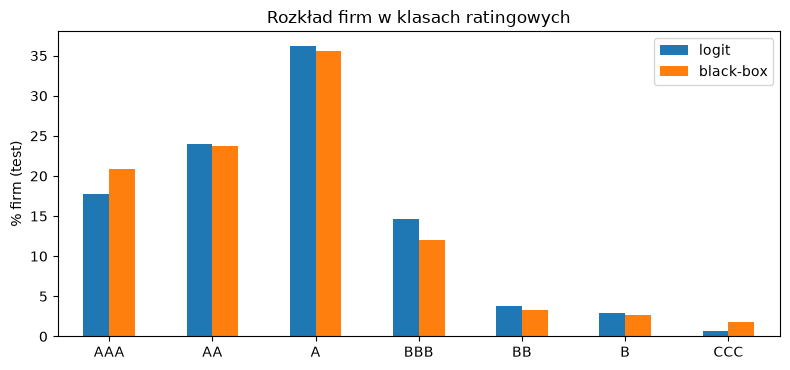

,logit,black-box
AAA,17.8,20.9
AA,24.0,23.8
A,36.2,35.6
BBB,14.7,12.0
BB,3.8,3.3
B,2.9,2.7
CCC,0.7,1.8


In [3]:
R = {m: {s: rating(PD[m][s]) for s in PD[m]} for m in PD}

dist = pd.DataFrame({m: pd.Series(R[m]['test']).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0) for m in PD})
hhi = (dist ** 2).sum()

print('HHI (koncentracja; równy rozkład na 7 klas = 0,143):', hhi.round(3).to_dict())

ax = (100 * dist).plot.bar(rot=0, figsize=(8, 3.8)); ax.set_ylabel('% firm (test)'); ax.set_title('Rozkład firm w klasach ratingowych')
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '07_rozklad_klas.png', dpi=150); plt.show()
(100 * dist).round(1)

**Wnioski:** ponad 75% firm trafia do AAA–A. HHI ≈ 0,25 (przy równym rozkładzie 0,143) oznacza umiarkowaną koncentrację. Po przesunięciu do 4% klasy BB–CCC są mało liczne.

----
## 3. Backtest klas

In [4]:
bt = {m: backtest(Y['test'], PD[m]['test'], R[m]['test']) for m in PD}

for m in PD:
    print(f"{m}: DR rośnie monotonicznie między klasami: {bool(np.all(np.diff(bt[m]['DR'].to_numpy()) >= 0))} | "
          f"światła: {bt[m]['światło'].value_counts().to_dict()}")

pd.concat(bt).to_csv(cfg.TAB_DIR / '07_backtest_test.csv')
pd.concat(bt).round(4)

logit: DR rośnie monotonicznie między klasami: True | światła: {'czerwone': 3, 'zielone': 2, 'żółte': 2}
black-box: DR rośnie monotonicznie między klasami: False | światła: {'czerwone': 4, 'zielone': 3}


n  udział  defaulty  oczekiwane  średnie PD      DR  \
          klasa                                                          
logit     AAA     80  0.1778         1      0.5413      0.0068  0.0125   
          AA     108  0.2400        12      1.5592      0.0144  0.1111   
          A      163  0.3622        22      5.5594      0.0341  0.1350   
          BBB     66  0.1467        15      4.1470      0.0628  0.2273   
          BB      17  0.0378         5      1.7201      0.1012  0.2941   
          B       13  0.0289         5      1.9811      0.1524  0.3846   
          CCC      3  0.0067         2      0.7137      0.2379  0.6667   
black-box AAA     94  0.2089         1      0.5839      0.0062  0.0106   
          AA     107  0.2378         9      1.5475      0.0145  0.0841   
          A      160  0.3556        25      5.4327      0.0340  0.1562   
          BBB     54  0.1200        16      3.4012      0.0630  0.2963   
          BB      15  0.0333         1      1.4306      0.0954  0.0667   
          B       12  0.0267         7      1.8426      0.1536  0.5833   
          CCC      8  0.0178         3      1.9045      0.2381  0.3750   

                 p dwumianowy  p Jeffreysa   światło  
          klasa                                       
logit     AAA          0.4191       0.2188   zielone  
          AA           0.0000       0.0000  czerwone  
          A            0.0000       0.0000  czerwone  
          BBB          0.0000       0.0000  czerwone  
          BB           0.0232       0.0110     żółte  
          B            0.0363       0.0178     żółte  
          CCC          0.1429       0.0512   zielone  
black-box AAA          0.4433       0.2394   zielone  
          AA           0.0000       0.0000  czerwone  
          A            0.0000       0.0000  czerwone  
          BBB          0.0000       0.0000  czerwone  
          BB           0.7777       0.6015   zielone  
          B            0.0008       0.0003  czerwone  
          CCC          0.2920       0.1773   zielone

W większości klas DR jest istotnie wyższy od średniego PD.

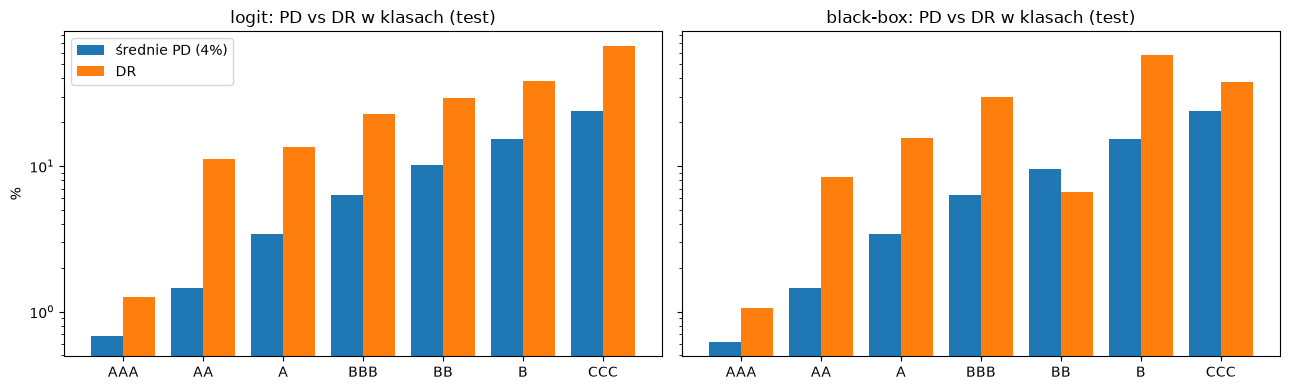

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, m in zip(axes, PD):
    t = bt[m]; x = np.arange(len(t))
    ax.bar(x - 0.2, 100 * t['średnie PD'], 0.4, label='średnie PD (4%)'); ax.bar(x + 0.2, 100 * t['DR'], 0.4, label='DR')
    ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_yscale('log'); ax.set_title(f'{m}: PD vs DR w klasach (test)')

axes[0].set_ylabel('%'); axes[0].legend(); plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '07_backtest.png', dpi=150); plt.show()

**Wnioski:** na wykresie DR jest w każdej klasie wyższy od PD, a różnica jest podobna dla obu modeli.

----
## 4. Próg decyzyjny z funkcji zysku

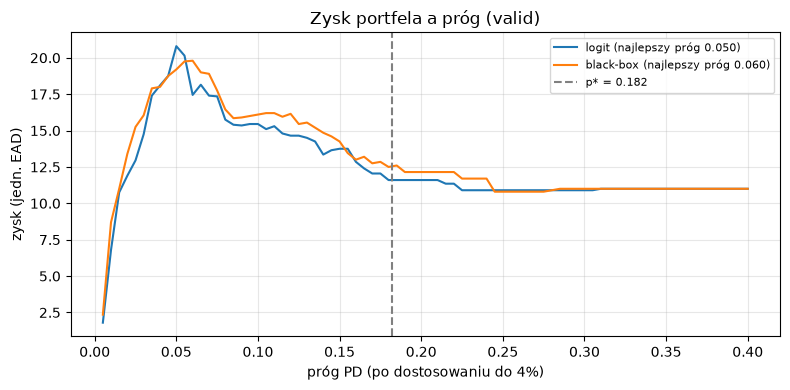

najlepszy próg na valid: {'logit': 0.049999999999999996, 'black-box': 0.06}


In [6]:
thr = np.linspace(0.005, 0.40, 80)
best_thr = {}
fig, ax = plt.subplots(figsize=(8, 4))

for m in PD:
    profit = np.array([economics(Y['valid'], PD[m]['valid'], t)['zysk'] for t in thr])
    best_thr[m] = float(thr[profit.argmax()])
    ax.plot(thr, profit, label=f'{m} (najlepszy próg {best_thr[m]:.3f})')

ax.axvline(P_STAR, ls='--', c='grey', label=f'p* = {P_STAR:.3f}'); ax.set_xlabel('próg PD (po dostosowaniu do 4%)')

ax.set_ylabel('zysk (jedn. EAD)'); ax.set_title('Zysk portfela a próg (valid)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '07_zysk_prog.png', dpi=150); plt.show()

print('najlepszy próg na valid:', best_thr)

----
## 5. Tabela decyzyjna (test)

In [7]:
rows = []

for m in PD:
    for name, t in [('p* teoretyczny', P_STAR), ('próg z valid', best_thr[m]), ('przyjmij wszystkich', 1.01)]:
        rows.append({'model': m, 'wariant': name, **economics(Y['test'], PD[m]['test'], t)})

dec = pd.DataFrame(rows).set_index(['model', 'wariant'])
dec.to_csv(cfg.TAB_DIR / '07_tabela_decyzyjna.csv')
dec.round(4)

próg  stopa akceptacji  DR wśród przyjętych  \
model     wariant                                                              
logit     p* teoretyczny       0.1818            0.9889               0.1303   
          próg z valid         0.0500            0.7800               0.0997   
          przyjmij wszystkich  1.0100            1.0000               0.1378   
black-box p* teoretyczny       0.1818            0.9756               0.1276   
          próg z valid         0.0600            0.8467               0.0971   
          przyjmij wszystkich  1.0100            1.0000               0.1378   

                               DR wśród odrzuconych  \
model     wariant                                     
logit     p* teoretyczny                     0.8000   
          próg z valid                       0.2727   
          przyjmij wszystkich                   NaN   
black-box p* teoretyczny                     0.5455   
          próg z valid                       0.3623   
          przyjmij wszystkich                   NaN   

                               EL przyjętych (oczekiwana)  \
model     wariant                                           
logit     p* teoretyczny                           6.8090   
          próg z valid                             3.4470   
          przyjmij wszystkich                      7.2999   
black-box p* teoretyczny                           6.1515   
          próg z valid                             3.8892   
          przyjmij wszystkich                      7.2644   

                               strata zrealizowana   zysk  
model     wariant                                          
logit     p* teoretyczny                     26.10  12.60  
          próg z valid                       15.75  15.85  
          przyjmij wszystkich                27.90  10.90  
black-box p* teoretyczny                     25.20  13.10  
          próg z valid                       16.65  17.75  
          przyjmij wszystkich                27.90  10.90

----
## 6. Porównanie decyzji modeli

In [8]:
acc = {m: PD[m]['test'] < best_thr[m] for m in PD}
agree = pd.crosstab(pd.Series(np.where(acc['logit'], 'przyjęty', 'odrzucony'), name='logit'),
                    pd.Series(np.where(acc['black-box'], 'przyjęty', 'odrzucony'), name='black-box'))
display(agree)
diff = acc['logit'] != acc['black-box']

print(f'zgodność decyzji: {1 - diff.mean():.1%} | firmy z różną decyzją: {diff.sum()}, DR wśród nich: '
      f'przyjęte tylko przez logit {Y["test"][acc["logit"] & ~acc["black-box"]].mean():.1%}, '
      f'tylko przez black-box {Y["test"][acc["black-box"] & ~acc["logit"]].mean():.1%}')

mig = pd.crosstab(pd.Series(R['logit']['test'], name='klasa logit'), pd.Series(R['black-box']['test'], name='klasa black-box'))

print('ta sama klasa:', f"{np.mean(np.asarray(R['logit']['test']) == np.asarray(R['black-box']['test'])):.1%}",
      '| różnica o najwyżej 1 klasę:', f"{np.mean(np.abs(R['logit']['test'].codes - R['black-box']['test'].codes) <= 1):.1%}")
mig

black-box,odrzucony,przyjęty
logit,,
odrzucony,62,37
przyjęty,7,344


zgodność decyzji: 90.2% | firmy z różną decyzją: 44, DR wśród nich: przyjęte tylko przez logit 14.3%, tylko przez black-box 8.1%
ta sama klasa: 67.3% | różnica o najwyżej 1 klasę: 99.3%


klasa black-box,AAA,AA,A,BBB,BB,B,CCC
klasa logit,,,,,,,
AAA,70,10,0,0,0,0,0
AA,23,70,15,0,0,0,0
A,1,27,119,15,1,0,0
BBB,0,0,25,34,7,0,0
BB,0,0,1,5,4,7,0
B,0,0,0,0,3,4,6
CCC,0,0,0,0,0,1,2


**Wnioski:** modele podejmują tę samą decyzję w 90% przypadków. 67% firm ma tę samą klasę, a 99% różni się najwyżej o jedną klasę.

----
## 7. Analiza kontrfaktyczna

In [9]:
L = joblib.load(cfg.ROOT / 'outputs/models/logit.joblib'); K = joblib.load(cfg.ROOT / 'outputs/models/kalibracja.joblib')

logit_model, F_LOG = L['model'], L['features']; kl = K['logit']          # model rekomendowany: karta scoringowa

base = build_base_frame(df); X_log = base[F_LOG]
pd_final = lambda X: shift(apply_cal(kl['metoda'], kl['kalibrator'], logit_model.predict_proba(X[F_LOG])[:, 1]), kl['delta'])
pv = pd.Series(PD['logit']['valid'], index=va)
log_firms = pv[np.asarray(R['logit']['valid'] == 'BB')]

firm_id = (log_firms - 0.10).abs().idxmin()                              # „typowa” BB: środek przedziału 8-12%
x0 = base.loc[[firm_id]]

print(f'firma {firm_id}: PD = {pd_final(x0)[0]:.2%}, klasa {rating(pd_final(x0))[0]}, default = {y.loc[firm_id]} | cel: PD < 8% (BBB)')

# realność: tylko cechy karty, na które firma ma wpływ (bez schematu sprawozdania i cech, których firma nie raportuje)
ACTIONABLE = [c for c in F_LOG if c not in CAT_COLS and c != 'wsk_liczba_dni_istnienia' and pd.notna(x0[c].iloc[0])]
# powiązania między cechami liczymy na wszystkich wskaźnikach liczbowych (także spoza karty) – wariant spójny
NUM_ALL = [c for c in base.columns if c not in CAT_COLS and pd.api.types.is_numeric_dtype(base[c])]
cf = Counterfactual(pd_final, base.loc[splits['train'], NUM_ALL], ACTIONABLE)

print('liczba cech, na które firma ma wpływ:', len(ACTIONABLE))

firma 273: PD = 10.21%, klasa BB, default = 1 | cel: PD < 8% (BBB)
liczba cech, na które firma ma wpływ: 8


**Wnioski:** analizę wykonujemy dla modelu rekomendowanego – karty scoringowej. Firma 273 z valid ma PD 10,2% (klasa BB), a celem jest BBB (PD < 8%). Zmieniać można tylko 8 cech liczbowych karty, na które firma ma wpływ – bez schematu sprawozdania i cech, których firma nie raportuje. Powiązania między cechami (wariant spójny) liczymy na wszystkich wskaźnikach, także spoza karty.

In [10]:
def show(sol, x0):
    rows = []
    x2 = sol['x']
    for c in cf.ref:
        a, b = x0[c].iloc[0], x2[c].iloc[0]
        if (pd.isna(a) and pd.notna(b)) or (pd.notna(a) and not np.isclose(a, b)):
            rows.append({'cecha': c, 'obecnie': a, 'po zmianie': b, 'percentyl obecnie': cf.pct(c, a) if pd.notna(a) else np.nan,
                         'percentyl po': cf.pct(c, b), 'zmiana bezpośrednia': c in sol['przesunięcia']})
    return pd.DataFrame(rows).set_index('cecha')

CF = {}
for variant, consistent in [('niezależny', False), ('spójny', True)]:
    sols = cf.search(x0, 0.08, consistent=consistent)
    CF[variant] = sols
    print(f'--- wariant {variant}: {len(sols)} rozwiązań; 3 najtańsze:')
    for s in sols[:3]:
        print({k: round(v, 2) for k, v in s['przesunięcia'].items()}, f"-> PD {s['PD po zmianie']:.2%}, zmienionych cech: {s['zmienione (z powiązanymi)']}")
show(CF['spójny'][0], x0).round(4) if CF['spójny'] else 'brak rozwiązania'

--- wariant niezależny: 61 rozwiązań; 3 najtańsze:
{'wsk_struktury_kapitalu': np.float64(0.05)} -> PD 7.44%, zmienionych cech: 1
{'wsk_struktury_kapitalu': np.float64(0.1)} -> PD 7.44%, zmienionych cech: 1
{'wsk_zadluzenia_krotkie': np.float64(-0.1)} -> PD 7.98%, zmienionych cech: 1
--- wariant spójny: 61 rozwiązań; 3 najtańsze:
{'wsk_struktury_kapitalu': np.float64(0.05)} -> PD 7.44%, zmienionych cech: 18
{'wsk_struktury_kapitalu': np.float64(0.1)} -> PD 7.44%, zmienionych cech: 18
{'wsk_zadluzenia_krotkie': np.float64(-0.1)} -> PD 7.98%, zmienionych cech: 17


,obecnie,po zmianie,percentyl obecnie,percentyl po,zmiana bezpośrednia
cecha,,,,,
wsk_kapital_do_aktywa,0.3198,0.3945,0.2581,0.3081,False
wsk_mnoznik_kap_wl,3.1268,2.5242,0.7465,0.6965,False
wsk_udzial_kap_wlasnego_aktywa_1,0.3198,0.3962,0.2687,0.3187,False
wsk_udzial_kap_wlasnego_aktywa_2,0.3505,0.4085,0.3421,0.3921,False
wsk_ogolnego_zadluzenia_1,0.6802,0.6021,0.7623,0.7122,False
wsk_ogolnego_zadluzenia_2,0.6802,0.6038,0.7465,0.6965,False
wsk_zadluzenie_kap_wlasnego,2.1268,1.5211,0.7613,0.7113,False
wsk_plynnosc_biez_1,1.4702,1.6578,0.3379,0.3882,False
wsk_struktury_kapitalu,0.4702,0.6574,0.2697,0.3197,True


**Wnioski:**
- najtańsza zmiana: wskaźnik struktury kapitału 0,47 → 0,66 (z 27. do 32. percentyla) → PD 7,4%; alternatywa: zadłużenie krótkoterminowe niższe o 10 percentyli → PD 8,0% (tuż przy granicy),
- karta jest funkcją schodkową: wystarczy przekroczyć najbliższą granicę przedziału WoE (dla struktury kapitału 0,59), dlatego mała zmiana daje skok PD,
- w wariancie spójnym ta sama zmiana pociąga 17 powiązanych wskaźników – to w praktyce różne wersje tej samej informacji (udział kapitału własnego, zadłużenie ogólne, mnożnik kapitału). Opisuje to realną zmianę: dokapitalizowanie albo spłatę części zobowiązań.

----
## 8. Kontrfakt vs SHAP i LIME

In [11]:
phi, phi0 = shap_logit(logit_model, X_log.loc[[firm_id]], X_log.loc[splits['train']])     # dekompozycja logitu
ad = LimeAdapter(X_log.loc[splits['train']], [c for c in F_LOG if c in CAT_COLS])
exp = LimeTabularExplainer(ad.encode(X_log.loc[splits['train']]), feature_names=F_LOG, categorical_features=ad.cat_idx,
                           mode='classification', random_state=cfg.SEED).explain_instance(
                               ad.encode(X_log.loc[[firm_id]])[0], ad.predict_fn(logit_model), num_features=8, num_samples=5000)
w = lime_weights(exp, F_LOG)
comp = pd.DataFrame({'SHAP (log-szanse)': phi.iloc[0], 'LIME (waga)': w}).fillna(0)
comp['ranga SHAP (podnosi ryzyko)'] = comp['SHAP (log-szanse)'].rank(ascending=False).astype(int)
cf_feats = {c for s in CF['niezależny'][:5] for c in s['cechy']}
comp['w 5 najtańszych kontrfaktach'] = comp.index.isin(cf_feats)
comp.to_csv(cfg.TAB_DIR / '07_kontrfakt_vs_shap.csv')
comp.sort_values('SHAP (log-szanse)', ascending=False).round(3)

,SHAP (log-szanse),LIME (waga),ranga SHAP (podnosi ryzyko),w 5 najtańszych kontrfaktach
wsk_zysk_zobowiazania,0.291,0.064,1,False
wsk_rotacja_wartosci_niewaterialnych,0.291,0.054,2,False
wsk_stopa_zysku_sprzedaz,0.269,0.053,3,False
wsk_poziom_kapitalu_obrotowego_netto,0.205,0.035,4,False
wsk_zadluzenia_krotkie,0.176,0.113,5,True
wsk_zast_kapitalu_podstawowego,0.162,0.024,6,False
wsk_struktury_kapitalu,0.159,-0.049,7,True
schemat_wsk_rzis,0.080,0.000,8,False
wsk_struktury_finansowania,-0.079,-0.039,9,False


**Wnioski:** SHAP wskazuje jako główne przyczyny ryzyka zysk / zobowiązania, rotację wartości niematerialnych i rentowność sprzedaży, a najtańsze kontrfakty dotyczą struktury kapitału (ranga 7 w SHAP) i zadłużenia krótkoterminowego (ranga 5). To nie jest sprzeczność: SHAP mówi, co obecnie najbardziej podnosi ryzyko, a kontrfakt – co najłatwiej zmienić, bo firma leży blisko granicy przedziału. LIME daje strukturze kapitału wagę ujemną (−0,05) przy dodatnim wkładzie SHAP (+0,16) – lokalne przybliżenie liniowe nie oddaje kształtu U.